## Generate cell population data for figure 3 for all six conditions

In [39]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "cellular_cycle")
sys.path.insert(0, "figures")

import fracprolif as fp

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [30]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)

In [5]:
# Setting initial concentrations
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


In [7]:
model.parameters['V_Di'].value

0.6

In [8]:
condition = "55 kPa erlotinib"
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1., 2., 5.,]


In [9]:
DIPs_di = dict([(conc, []) for conc in concs])
population_dfs = dict([(conc, []) for conc in concs])
cell_counts_di = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

init = 10
run_time = 120
observed_cells_time = 120

In [10]:
def run_treatment(inhib_name, inhib_conc):
    model.parameters[inhib_name].value = inhib_conc
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model,
                                                                           ECM_conditions, condition,
                                                                           sampled_parameter_names, thr=[0.26, 0.14],
                                                                           return_plot=False, bypass=True)
    return cells, cell_count, population_df

In [11]:
#fig, ax = make_fig(cell_count, run_time, title=condition)
# concs = [1, 2, 5, 10]
n=0
for conc in concs:
    for i in range(5):
        cells, cell_count, population_df = run_treatment('CycDi_0', conc)
        cell_counts_di[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_di[conc].append(dip_rate)
        population_dfs[conc].append(population_df)
    n+=1
        

55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotin

In [12]:
DIPs_di

{0: [0.02627941826143762,
  0.02881504352924141,
  0.030543847480277178,
  0.024540159296380804,
  0.027212381618828066],
 0.001: [0.028018980554304827,
  0.02772731427058261,
  0.026143496019485124,
  0.02856321436840585,
  0.02600192018551432],
 0.01: [0.02840634002446495,
  0.02718346643284013,
  0.028340396250837088,
  0.02755069719915086,
  0.026565240840951854],
 0.025: [0.021645470283631184,
  0.023242104576654384,
  0.026321492237603022,
  0.024025220146541005,
  0.026680978001814046],
 0.05: [0.021248833560308034,
  0.029613629549187774,
  0.02346912171145186,
  0.025401993081666335,
  0.02182582779914845],
 0.1: [0.01766159198655015,
  0.02083904437609369,
  0.02139305801290295,
  0.019908963866875448,
  0.021488323694342334],
 0.2: [0.016730271662990823,
  0.01394819973499831,
  0.016431403880460573,
  0.009342057345342457,
  0.013997807484151314],
 0.3: [0.008973391250155982,
  0.01234953030249895,
  0.00785554453135523,
  0.011882909911858065,
  0.00944805280794013],
 0.4:

In [13]:
DIPs_di_df = pd.DataFrame(DIPs_di.values(), index=DIPs_di.keys())
DIPs_di_df


,0,1,2,3,4
0.000,0.026279,0.028815,0.030544,0.024540,0.027212
0.001,0.028019,0.027727,0.026143,0.028563,0.026002
0.010,0.028406,0.027183,0.028340,0.027551,0.026565
0.025,0.021645,0.023242,0.026321,0.024025,0.026681
0.050,0.021249,0.029614,0.023469,0.025402,0.021826
0.100,0.017662,0.020839,0.021393,0.019909,0.021488
0.200,0.016730,0.013948,0.016431,0.009342,0.013998
0.300,0.008973,0.012350,0.007856,0.011883,0.009448
0.400,0.007715,0.005103,0.007964,0.004766,0.008682
0.500,-0.000872,0.002447,0.003287,0.005305,0.004691


Text(0, 0.5, 'DIP rate, 1/h')

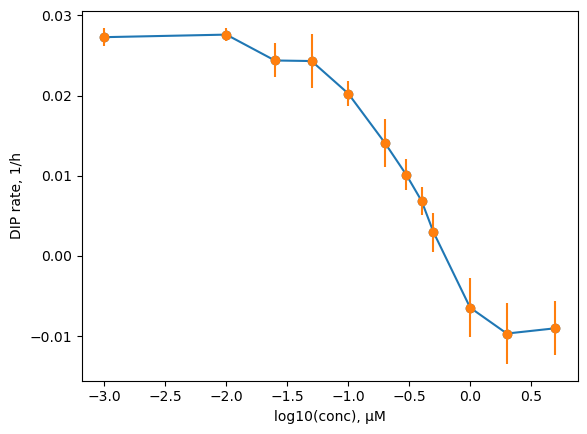

In [14]:
plt.plot(np.log10(concs), DIPs_di_df.mean(axis=1), 'o-')
plt.errorbar(np.log10(concs), DIPs_di_df.mean(axis=1), yerr=DIPs_di_df.std(axis=1), fmt='o')
plt.xlabel('log10(conc), µM')
plt.ylabel('DIP rate, 1/h')

### Save DIP rates by CDK4/6i conc

In [31]:
fn = '../data/DIPrates_CDK4-6i_df.csv'
if not Path(fn).exists() or OVERWRITE:
    print(f'Saving to {fn}')
    DIPs_di_df.to_csv(fn)
else:
    print(f'File exists: {fn}')

Saving to ../data/DIPrates_CDK4-6i_df.csv


In [16]:
# def calc_rates(population_df):
#     population_history = population_df
#     parameters_sim = {}
#     if len(population_history) > 0:
#         number_of_deaths = len(population_history) - (population_history['Event'] == 'Apoptosis').value_counts()[0]
#         cell_time_total = sum(population_history['Lifetime'])
#         parameters_sim['a'] = number_of_deaths / cell_time_total
#     else:
#         parameters_sim['a'] = np.nan
#         number_of_deaths = np.nan

#     population_df = population_history[population_history['Starting Cell'] == False]
#     mitotic_lifespans = population_df['Lifetime'][population_df['Event'] == 'Mitosis']
#     censored_lifespans = population_df['Lifetime'][population_df['Event'] == 'End of experiment']

#     if len(mitotic_lifespans) > 2:
#         m = fp.mle(mitotic_lifespans, censored_lifespans)
#         parameters_sim['mu'] = m['x'][0]
#         parameters_sim['sigma'] = m['x'][1]
#         parameters_sim['lambda'] = m['x'][2]
#         parameters_sim.update(fp.q_rates(m))
#     else:
#         parameters_sim['d'] = np.nan
#         parameters_sim['q'] = np.nan
#         parameters_sim['mu'] = np.nan
#         parameters_sim['sigma'] = np.nan
#         parameters_sim['lambda'] = np.nan

#     return parameters_sim, number_of_deaths, len(mitotic_lifespans)

# def plot_numberdeaths(concs, population_dfs, title="Unknown Condition"):
#     fig = plt.figure()
#     ax = fig.add_subplot(1, 1, 1)

#     ax.set_xlabel('Conc (um)')
#     ax.set_ylabel('Death Count')
#     ax.set_xscale("log")
#     ax.set_xlim(1.0e-10, 1.0e-4)
#     # ax.set_ylim(-0.01,0.03)
#     # plt.text(0,4.5,title)
#     for conc in concs:
#         a_rates = []
#         deaths = []
#         n = len(population_dfs[0])

#         for num in range(n):
#             tmp_rates, tot_deaths, _ = calc_rates(population_dfs[conc][num])
#             a_rates.append(tmp_rates['a'])
#             deaths.append(tot_deaths)

#         tmp_c = [conc * 10e-7] * n
#         ax.scatter(tmp_c, deaths, color='black')

#     return fig, ax





In [17]:
rates, death_num, div_num = calc_rates(population_df)

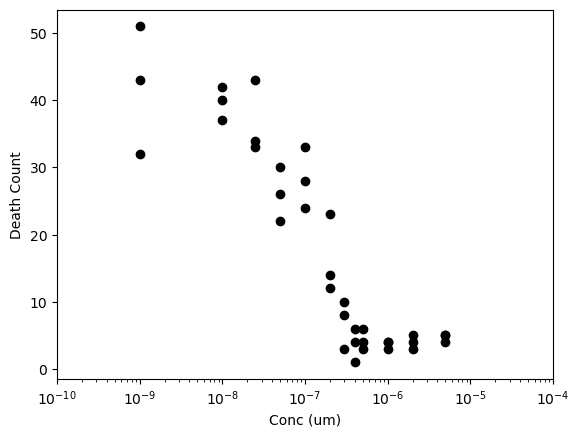

In [18]:
fig, ax = plot_numberdeaths(concs, population_dfs, title="Unknown Condition")

In [19]:
# all_div_len = {0: [27.47252747252747, 27.839643652561247, 27.716186252771617],
#  0.001: [27.77777777777778, 27.716186252771617, 28.28054298642534],
#  0.01: [28.538812785388128, 28.86836027713626, 28.409090909090907],
#  0.025: [30.339805825242717, 29.274004683840747, 30.048076923076927],
#  0.05: [32.808398950131235, 31.9693094629156, 32.552083333333336],
#  0.075: [34.62603878116344, 34.24657534246575, 33.24468085106383],
#  0.1: [37.20238095238095, 36.231884057971016, 35.51136363636363],
#  0.25: [44.642857142857146, 43.40277777777778, 46.125461254612546],
#  0.5: [56.81818181818181, 55.80357142857143, 58.13953488372093],
#  1: [62.5, 62.5, 68.30601092896175],
#  2: [70.2247191011236, 77.63975155279502, 76.21951219512195],
#  5: [78.125, 74.4047619047619, 75.75757575757576],
#  10: [89.28571428571429, 83.33333333333333, 82.78145695364238]}

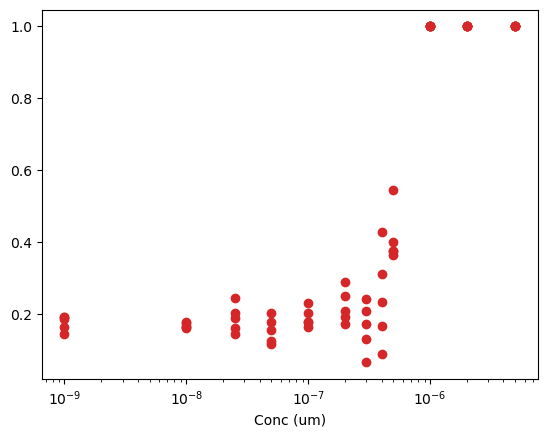

In [20]:
fig, ax = plot_divdeath_totals(concs, population_dfs, title="Unknown Condition")
# ax.set_ylim(0, 1)
# ax.set_xlim(0.0003, 50)

In [21]:
# no_divs = {0: [0.0061512720830667784, 0.005354565348977975, 0.004729343606518611],
#  0.001: [0.005728232715680414, 0.004926530437390224, 0.004906570715950444],
#  0.01: [0.006281249214843848, 0.0052431511338314335, 0.004284091120755491],
#  0.025: [0.005657708628005658, 0.005955642375586631, 0.005131055714713302],
#  0.05: [0.006316454363617221, 0.006013807702484905, 0.005451373746184037],
#  0.075: [0.0052501476604029495, 0.005067088248408934, 0.0055289347585698485],
#  0.1: [0.007584951456310679, 0.006427595811350063, 0.004793264421473824],
#  0.25: [0.005138416083242341, 0.004911276718413016, 0.006476851731910153],
#  0.5: [0.004729493532931669, 0.004649000464900046, 0.007585641897017326],
#  1: [0.005850661856122473, 0.004396570674873598, 0.0050784856879039705],
#  2: [0.005396290050590219, 0.004602903665062042, 0.007363553356307619],
#  5: [0.005354440693749273, 0.006975446428571428, 0.007466252538525863],
#  10: [0.005457770500750442, 0.0032538313864575535, 0.004225999081304547]}

In [22]:
population_dfs.keys()

dict_keys([0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 2.0, 5.0])

### Absolute DIP rate values vs CDK4/6i conc 

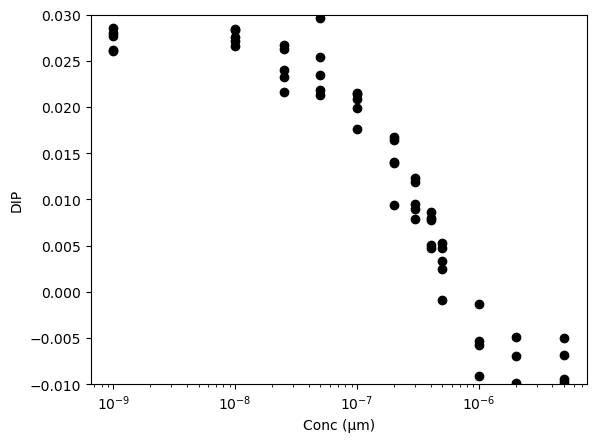

In [23]:
fig, ax = plot_dip(concs, DIPs_di, title="Unknown Condition")
# ax.set_xlim(0.0003, 50)

### Save files of cell counts over time from each of 5 simulations per condition

In [24]:
cell_counts_dil = {}
for cond in cell_counts_di:
    tmp = [run.tolist() for run in cell_counts_di[cond]]
    cell_counts_dil.update({cond: tmp})

In [25]:
# a_rates_dil = {}
# for cond in a_rate_di:
#     tmp = [run for run in a_rate_di[cond]]
#     a_rates_dil.update({cond: tmp})

In [32]:
import json

fn = SAVE_DIR / 'cdk46i_0.4_cellcounts.json'

if not fn.exists() or OVERWRITE:
    print(f'Writing {fn}')
    with open(fn, 'w') as f: 
        json.dump(cell_counts_dil, f)
else:
    print(f'{fn} exists. Skipping.')

Writing /Users/darren/ECM_mod_output/cdk46i_0.4_cellcounts.json


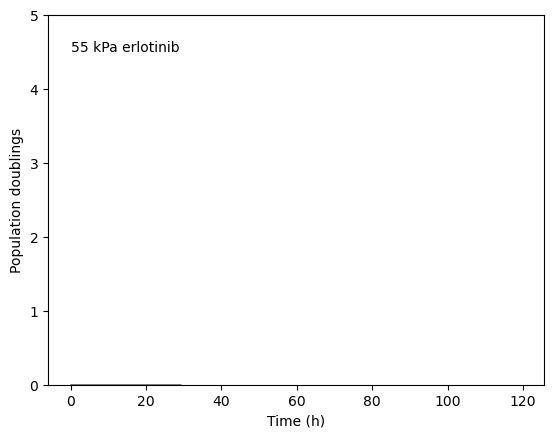

In [27]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

### Simulation using 20 cells for a total of 200 cell IMTs (for G1 calculation)

In [37]:
model.parameters['CycDi_0'].value = 0.4

In [52]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, 
            sampled_parameter_names, IMTs_count, inhib, SAVE_DIR):
    all_IMTs = []
    n = 0
    while len(all_IMTs) < IMTs_count:
        check, population_df, cells, cell_count = Cell_Population_Simulation(init, run_time, observed_cells_time, model,
                                                                             ECM_conditions, condition,
                                                                             sampled_parameter_names, thr=[0.26, 0.14],
                                                                             return_plot=False, bypass=True)
        IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True, verbose=True) # manually setting verbose to True
        all_events_simulated = call_events(run_time, IMT_eoe_counts)

        mits = all_events_simulated.loc[all_events_simulated['event'] == 'mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x, 1) for x in mits_list]

        IMT_tmp, s_m_tmp, g1_tmp = SMs_G1s_IMTs_extraction(cells)

        if n == 0:
            all_IMTs = mits_list_r
            all_g1s = g1_tmp
        else:
            all_IMTs.extend(mits_list_r)
            all_g1s.extend(g1_tmp)
        
        print(f'runIMT round {n} has {len(all_IMTs)} IMT values')
        
        n += 1

    filename_IMT = SAVE_DIR / f'IMTs_{condition}_{inhib}.csv'
    filename_g1 = SAVE_DIR / f'G1s_{condition}_{inhib}.csv'
    print(f'Saving {filename_IMT} and {filename_g1}...')
    np.savetxt(filename_IMT, all_IMTs, delimiter=',')
    np.savetxt(filename_g1, all_g1s, delimiter=',')

In [53]:
runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count=200, inhib='CDK46i', SAVE_DIR=SAVE_DIR)


55 kPa erlotinib


TypeError: retrieve_cellState() got an unexpected keyword argument 'verbose'